# Model Evaluation Summary

Aggregated results across solver accuracy, cache performance, and inference (OCR) results.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import glob
import os
import re

## 1. Solver Accuracy, Model Comparison

In [2]:
summary_files = sorted(glob.glob(f'results/summary_*.csv'))
summaries = pd.concat([pd.read_csv(f) for f in summary_files], ignore_index=True)
summaries = summaries.sort_values('accuracy', ascending=False).reset_index(drop=True)
summaries

,model,total_questions,correct,incorrect,accuracy
0,gemma-4-12b-qat:latest,60,45,15,75.00
1,ministral-3:8b,60,43,17,71.67
2,hf.co/unsloth/gemma-4-E2B-it-GGUF:Q4_K_M,60,33,27,55.00
3,llama3.1:8b,60,33,27,55.00
4,qwen2.5:7b-instruct,60,28,32,46.67
5,qwen3.5:9b,60,18,42,30.00


In [3]:
summaries['model'] = ['gemma-4:12b-qat','ministral-3:8b','llama-3.1:8b','qwen-2.5:7b-instruct','gemma-4:E2B-it','qwen-3.5:9b']

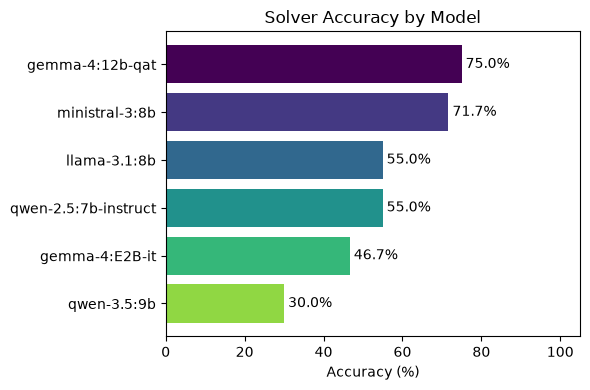

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = plt.cm.viridis([i / len(summaries) for i in range(len(summaries))])
bars = ax.barh(summaries['model'], summaries['accuracy'], color=colors)
ax.set_xlabel('Accuracy (%)')
ax.set_title('Solver Accuracy by Model')
ax.set_xlim(0, 105)
for bar, val in zip(bars, summaries['accuracy']):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%', va='center', fontsize=10)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('model_accuracy', dpi=300, bbox_inches='tight')
plt.show()

### Per-Category Accuracy (aggregated across models)

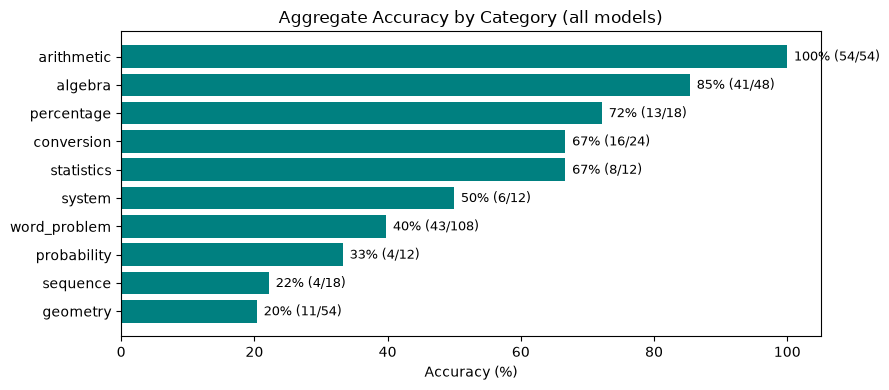

In [5]:
output_files = sorted(glob.glob(f'results/output_*.csv'))
all_outputs = []
for f in output_files:
    model = os.path.basename(f).replace('output_', '').replace('.csv', '')
    df = pd.read_csv(f)
    df['model'] = model
    all_outputs.append(df)
all_outputs = pd.concat(all_outputs, ignore_index=True)

cat_acc = all_outputs.groupby('category').agg(
    total=('is_correct', 'count'),
    correct=('is_correct', 'sum')
).reset_index()
cat_acc['accuracy'] = (cat_acc['correct'] / cat_acc['total'] * 100).round(1)
cat_acc = cat_acc.sort_values('accuracy', ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(cat_acc['category'], cat_acc['accuracy'], color='teal')
ax.set_xlabel('Accuracy (%)')
ax.set_title('Aggregate Accuracy by Category (all models)')
ax.set_xlim(0, 105)
for i, row in cat_acc.iterrows():
    ax.text(row['accuracy'] + 1, list(cat_acc['category']).index(row['category']),
            f"{row['accuracy']:.0f}% ({int(row['correct'])}/{int(row['total'])})", va='center', fontsize=9)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 2. Cache Performance

deterministic (cold_ms < 10ms), model inference (cold_ms >= 10ms).

In [6]:
COLD_MS_THRESHOLD = 10

In [7]:
cache_output_files = sorted(glob.glob(f'results/cache_output_*.csv'))
cache_dfs = []

In [8]:
for f in cache_output_files:
    model = os.path.basename(f).replace('cache_output_', '').replace('.csv', '')
    df = pd.read_csv(f)
    df['model'] = model
    cache_dfs.append(df)

In [9]:
cache_all = pd.concat(cache_dfs, ignore_index=True)
cache_all['type'] = cache_all['cold_ms'].apply(lambda x: 'deterministic' if x < COLD_MS_THRESHOLD else 'model')

In [10]:

cache_all.groupby(['model', 'type']).size().unstack(fill_value=0)

type,deterministic,model
model,,
gemma-4-12b-qat:latest,24,36
hf.co_unsloth_gemma-4-E2B-it-GGUF:Q4_K_M,23,37


In [11]:
cache_all['model'] = cache_all['model'].map({'gemma-4-12b-qat:latest':'gemma-4:12b-qat','hf.co_unsloth_gemma-4-E2B-it-GGUF:Q4_K_M':'gemma-4:E2B-it'})

In [12]:
det = cache_all[cache_all['type'] == 'deterministic']
mdl = cache_all[cache_all['type'] == 'model']

In [50]:
colors = plt.cm.viridis([i / 3 for i in range(3)])
w = 0.25

In [69]:
def dual_axis_cache_plot(df, title, filename):
    models = sorted(df['model'].unique())
    x = range(len(models))
    avg_cold = [df[df['model'] == m]['cold_ms'].mean() for m in models]
    avg_hit  = [df[df['model'] == m]['hit_ms'].mean() for m in models]
    avg_spd  = [df[df['model'] == m]['speedup'].mean() for m in models]

    fig, ax1 = plt.subplots(figsize=(8, 4.5))
    ax2 = ax1.twinx()

    b1 = ax1.bar([i - w for i in x], avg_cold, w, label='Avg Cold (ms)', color=colors[0])
    b2 = ax1.bar(list(x), avg_hit, w, label='Avg Hit (ms)', color=colors[1])
    b3 = ax2.bar([i + w for i in x], avg_spd, w, label='Avg Speedup (×)', color=colors[2])

    ax1.set_xticks(list(x))
    ax1.set_xticklabels(models)
    ax1.set_yscale('log')
    ax1.set_ylabel('Time (ms)')
    ax2.set_ylabel('Speedup (×)')

    handles = [b1, b2, b3]
    labels = [h.get_label() for h in handles]
    ax1.legend(handles, labels, fontsize=8, loc='lower center',
               bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False)

    ax1.set_title(title, y=1.09)

    plt.tight_layout(rect=[0, 0.02, 0.95, 0.95])
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

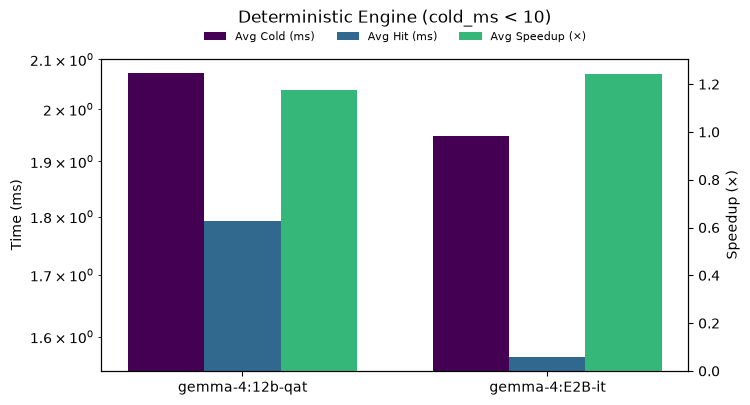

In [70]:
dual_axis_cache_plot(det, 'Deterministic Engine (cold_ms < 10)', 'cache_effectiveness_det.png')

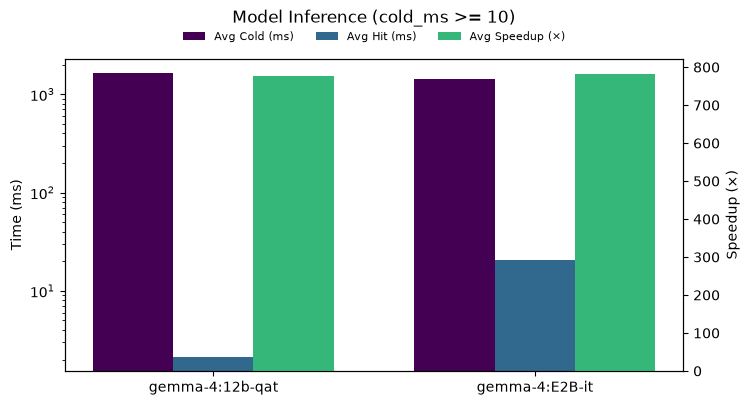

In [71]:
dual_axis_cache_plot(mdl, 'Model Inference (cold_ms >= 10)', 'cache_effectiveness_mdl.png')

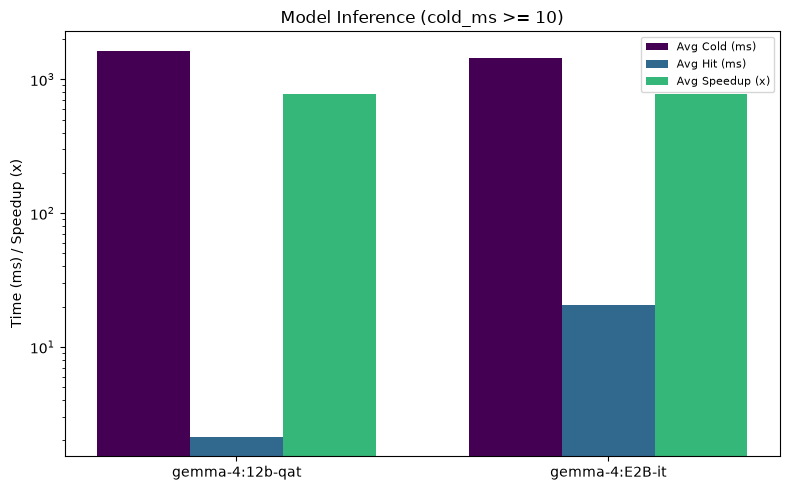

In [49]:
models2 = sorted(mdl['model'].unique())

fig2, ax2 = plt.subplots(figsize=(8, 5))

x2 = range(len(models2))
avg_cold2 = [mdl[mdl['model'] == m]['cold_ms'].mean() for m in models2]
avg_hit2 = [mdl[mdl['model'] == m]['hit_ms'].mean() for m in models2]
avg_spd2 = [mdl[mdl['model'] == m]['speedup'].mean() for m in models2]

ax2.bar([i - w for i in x2], avg_cold2, w, label='Avg Cold (ms)', color=colors[0])
ax2.bar(list(x2), avg_hit2, w, label='Avg Hit (ms)', color=colors[1])
ax2.bar([i + w for i in x2], avg_spd2, w, label='Avg Speedup (x)', color=colors[2])

ax2.set_xticks(list(x2))
ax2.set_xticklabels(models2)
ax2.set_yscale('log')
ax2.set_title('Model Inference (cold_ms >= 10)')
ax2.legend(fontsize=8, loc='upper right')
ax2.set_ylabel('Time (ms) / Speedup (x)')

plt.tight_layout()
plt.savefig('cache_effectiveness_mdl.png', dpi=300, bbox_inches='tight')
plt.show()

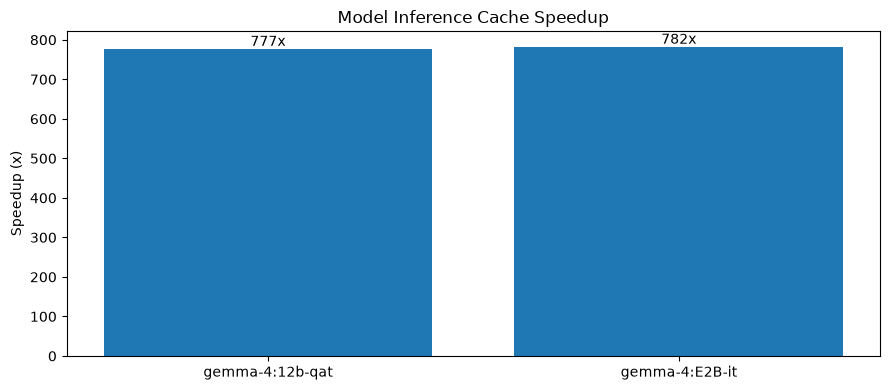

In [45]:
models = sorted(mdl['model'].unique())
fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(models))
spd = [mdl[mdl['model'] == m]['speedup'].mean() for m in models]
bars = ax.bar(list(x), spd)
ax.set_xticks(list(x))
ax.set_xticklabels(models)
ax.set_ylabel('Speedup (x)')
ax.set_title('Model Inference Cache Speedup')
for bar, val in zip(bars, spd):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(spd)*0.01,
            f'{val:.0f}x', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

## 3. Inference Results (OCR Model Comparison)

In [15]:
def tokenize_latex(s):
    """Split LaTeX into tokens: commands, numbers, operators, whitespace, single chars."""
    if not isinstance(s, str):
        return []
    tokens = re.findall(
        r'\\[a-zA-Z]+|'   # commands like \int, \cos
        r'\\[^a-zA-Z]|'   # escaped chars like \, \;
        r'\d+\.?\d*|'     # numbers
        r'[a-zA-Z]|'      # single letters
        r'\s+|'           # whitespace
        r'[{}+\-=^_\\;,./@#%&*<>~]',  # punctuation/operators
        s
    )
    return tokens

In [16]:
def token_accuracy(gt, pred):
    """Token-level accuracy using longest common subsequence ratio."""
    gt_tokens = tokenize_latex(gt)
    pred_tokens = tokenize_latex(pred)
    if len(gt_tokens) == 0:
        return 1.0 if len(pred_tokens) == 0 else 0.0
    if len(pred_tokens) == 0:
        return 0.0
    # LCS length
    m, n = len(gt_tokens), len(pred_tokens)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if gt_tokens[i-1] == pred_tokens[j-1]:
                dp[i][j] = dp[i-1][j-1] + 1
            else:
                dp[i][j] = max(dp[i-1][j], dp[i][j-1])
    lcs_len = dp[m][n]
    return lcs_len / max(m, n)

In [17]:
inf = pd.read_csv(f'data/inference_results.csv')

In [18]:
ocr_models = ['nougat-base', 'nougat-latex-base', 'pix2tex']

In [19]:
anomaly_masks = {}
for m in ocr_models:
    lev = inf[f'{m}_levenshtein']
    q1, q3 = lev.quantile(0.25), lev.quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 3 * iqr
    anomaly_masks[m] = lev > upper
    print(f'{m}: upper_fence={upper:.0f}, anomalies={anomaly_masks[m].sum()}')

nougat-base: upper_fence=841, anomalies=2
nougat-latex-base: upper_fence=173, anomalies=11
pix2tex: upper_fence=285, anomalies=13


In [20]:
any_anomaly = pd.Series(False, index=inf.index)
for m in ocr_models:
    any_anomaly = any_anomaly | anomaly_masks[m]
print(f'\nTotal rows with at least one anomaly: {any_anomaly.sum()} / {len(inf)}')


Total rows with at least one anomaly: 25 / 200


In [21]:
for m in ocr_models:
    pred_col = f'{m}_output'
    inf[f'{m}_token_acc'] = inf.apply(lambda r: token_accuracy(r['latex'], r[pred_col]), axis=1)

In [22]:
pix_fail = inf[(inf['pix2tex_exact_match'] == False) & (~any_anomaly)].copy()

In [23]:
lev_cols = [f'{m}_levenshtein' for m in ocr_models]
ned_cols = [f'{m}_normalized_edit_distance' for m in ocr_models]

In [24]:
pix_fail['penalty_levenshtein'] = pix_fail[lev_cols].max(axis=1)
pix_fail['penalty_ned'] = pix_fail[ned_cols].max(axis=1)
pix_fail['penalty_model'] = pix_fail[lev_cols].idxmax(axis=1).str.replace('_levenshtein', '')

token_acc_cols = [f'{m}_token_acc' for m in ocr_models]
pix_fail['penalty_token_acc'] = pix_fail[token_acc_cols].min(axis=1) * 100

In [25]:
print(f'pix2tex failures (non-anomalous): {len(pix_fail)}')
print(f'Penalty Levenshtein — mean: {pix_fail["penalty_levenshtein"].mean():.1f}, median: {pix_fail["penalty_levenshtein"].median():.1f}')
print(f'Penalty NED — mean: {pix_fail["penalty_ned"].mean():.2f}, median: {pix_fail["penalty_ned"].median():.2f}')
print(f'\nPenalty source model distribution:')
print(pix_fail['penalty_model'].value_counts().to_string())

pix2tex failures (non-anomalous): 175
Penalty Levenshtein — mean: 149.7, median: 160.0
Penalty NED — mean: 0.89, median: 0.88

Penalty source model distribution:
penalty_model
nougat-base          94
nougat-latex-base    43
pix2tex              38


In [26]:
rows = []
for m in ocr_models:
    for style in ['printed', 'handwritten']:
        subset = inf[inf['render_style'] == style]
        rows.append({
            'model': m,
            'render_style': style,
            'avg_levenshtein': subset[f'{m}_levenshtein'].mean(),
            'avg_ned': subset[f'{m}_normalized_edit_distance'].mean(),
            'token_accuracy': subset[f'{m}_token_acc'].mean() * 100,
        })

In [27]:
# pix2tex penalty rows
for style in ['printed', 'handwritten']:
    subset = pix_fail[pix_fail['render_style'] == style]
    if not subset.empty:
        rows.append({
            'model': 'pix2tex (penalized)',
            'render_style': style,
            'avg_levenshtein': subset['penalty_levenshtein'].mean(),
            'avg_ned': subset['penalty_ned'].mean(),
            'token_accuracy': subset['penalty_token_acc'].mean()
        })

ocr_summary = pd.DataFrame(rows)
ocr_summary.round(2)

,model,render_style,avg_levenshtein,avg_ned,token_accuracy
0,nougat-base,printed,176.93,0.67,37.22
1,nougat-base,handwritten,150.86,0.68,36.57
2,nougat-latex-base,printed,65.88,0.76,34.17
3,nougat-latex-base,handwritten,180.80,0.77,31.23
4,pix2tex,printed,64.44,0.84,19.79
5,pix2tex,handwritten,118.74,0.86,17.29
6,pix2tex (penalized),printed,146.11,0.89,14.36
7,pix2tex (penalized),handwritten,153.73,0.90,12.97


In [28]:
plot_models = ocr_models + ['pix2tex (penalized)']
plot_models.remove('pix2tex')
styles = ['printed', 'handwritten']

In [29]:
cat_inf = []
for m in ocr_models:
    ned_col = f'{m}_normalized_edit_distance'
    for cat in inf['category'].unique():
        subset = inf[inf['category'] == cat]
        cat_inf.append({
            'model': m,
            'category': cat,
            'avg_levenshtein': subset[f'{m}_levenshtein'].mean(),
            'avg_ned': subset[ned_col].mean(),
            'avg_token_acc': subset[f'{m}_token_acc'].mean()
        })

In [30]:
# pix2tex penalty by category
for cat in inf['category'].unique():
    subset = pix_fail[pix_fail['category'] == cat]
    if not subset.empty:
        cat_inf.append({
            'model': 'pix2tex (penalized)',
            'category': cat,
            'avg_levenshtein': subset['penalty_levenshtein'].mean(),
            'avg_ned': subset['penalty_ned'].mean(),
            'avg_token_acc': subset['penalty_token_acc'].mean()
        })

In [31]:
cat_inf_df = pd.DataFrame(cat_inf)

In [32]:
pivot = cat_inf_df.pivot(index='category', columns='model', values='avg_levenshtein').round(1)
pivot

model,nougat-base,nougat-latex-base,pix2tex,pix2tex (penalized)
category,,,,
equation,100.4,69.4,97.5,67.0
word_problem,220.2,171.2,86.3,222.6


In [33]:
pivot = cat_inf_df.pivot(index='category', columns='model', values='avg_ned').round(1)
pivot

model,nougat-base,nougat-latex-base,pix2tex,pix2tex (penalized)
category,,,,
equation,0.5,0.8,0.8,0.9
word_problem,0.8,0.8,0.9,0.9


In [34]:
pivot = cat_inf_df.pivot(index='category', columns='model', values='avg_token_acc').round(2)
pivot

model,nougat-base,nougat-latex-base,pix2tex,pix2tex (penalized)
category,,,,
equation,0.62,0.34,0.26,22.31
word_problem,0.14,0.32,0.12,6.11


In [35]:
ocr_summary

,model,render_style,avg_levenshtein,avg_ned,token_accuracy
0,nougat-base,printed,176.930000,0.674626,37.221513
1,nougat-base,handwritten,150.860000,0.677351,36.567442
2,nougat-latex-base,printed,65.880000,0.763895,34.167776
3,nougat-latex-base,handwritten,180.800000,0.774624,31.226132
4,pix2tex,printed,64.440000,0.838234,19.791907
5,pix2tex,handwritten,118.740000,0.861236,17.286320
6,pix2tex (penalized),printed,146.108696,0.891686,14.361001
7,pix2tex (penalized),handwritten,153.734940,0.895425,12.973644


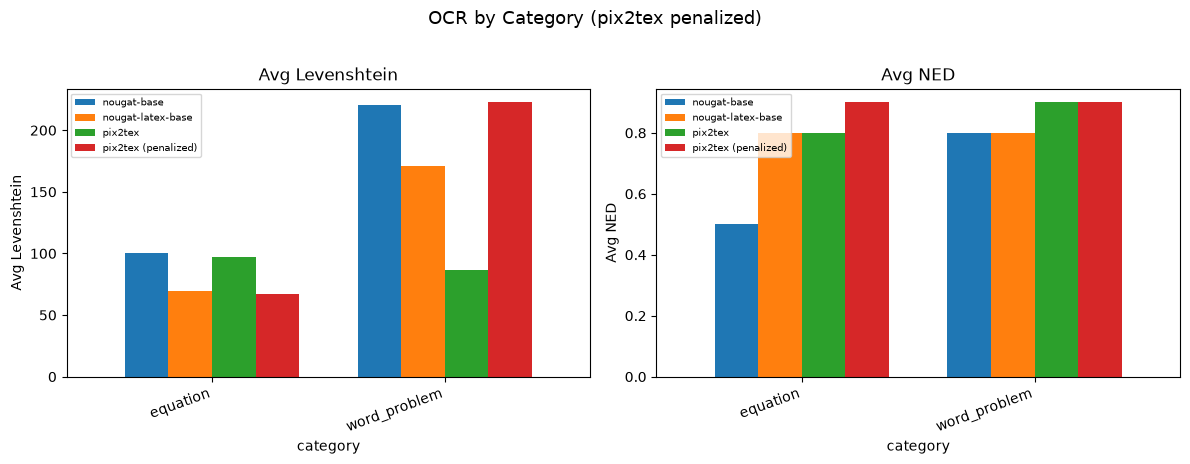

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in zip(axes, ['avg_levenshtein', 'avg_ned'], ['Avg Levenshtein', 'Avg NED']):
    pivot = cat_inf_df.pivot(index='category', columns='model', values=metric).round(1)
    plot_cols = [c for c in ocr_models + ['pix2tex (penalized)'] if c in pivot.columns]
    pivot[plot_cols].plot(kind='bar', ax=ax, width=0.75)
    ax.set_title(title)
    ax.set_ylabel(title)
    ax.legend(fontsize=7)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

plt.suptitle('OCR by Category (pix2tex penalized)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

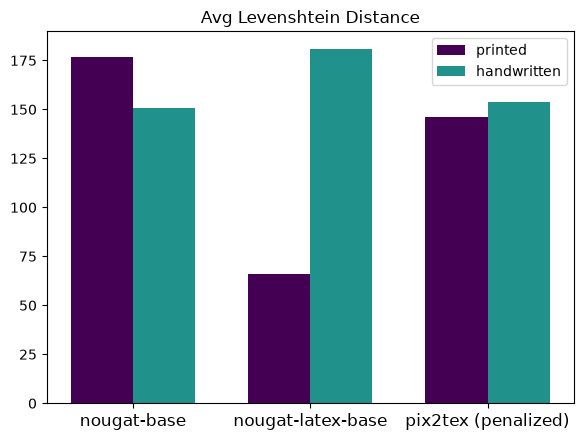

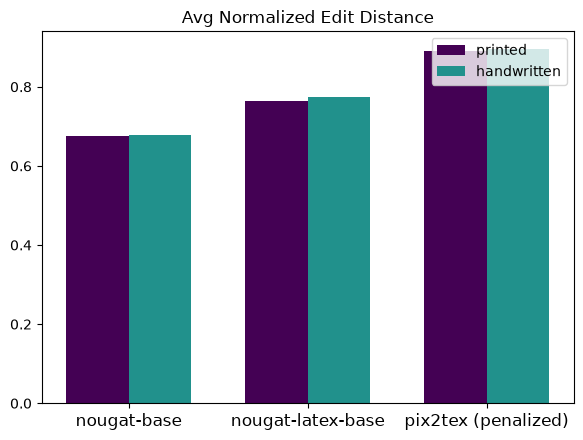

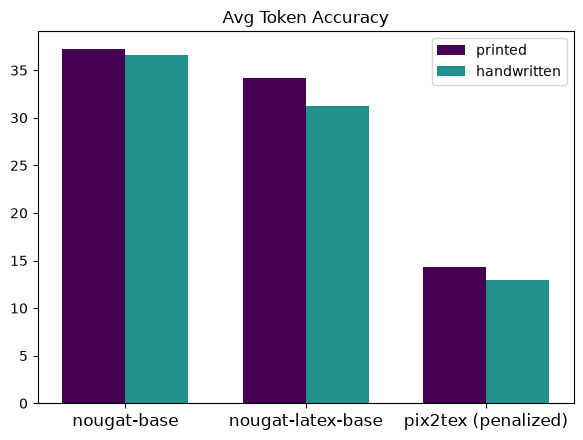

In [37]:
x = range(len(plot_models))
w = 0.35
colors = plt.cm.viridis([i / 2 for i in range(2)])

metrics = ['avg_levenshtein', 'avg_ned', 'token_accuracy']
titles = ['Avg Levenshtein Distance', 'Avg Normalized Edit Distance', 'Avg Token Accuracy']
filenames = ['levenshtein.png', 'ned.png', 'token_accuracy.png']

for metric, title, filename in zip(metrics, titles, filenames):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    
    for i, style in enumerate(styles):
        vals = []
        for m in plot_models:
            row = ocr_summary[(ocr_summary['model'] == m) & (ocr_summary['render_style'] == style)]
            vals.append(row[metric].values[0] if len(row) > 0 else 0)
        offset = (i - 0.5) * w
        ax.bar([xi + offset for xi in x], vals, w, label=style,
               color=colors[0] if style == 'printed' else colors[1])
    
    ax.set_xticks(list(x))
    ax.set_xticklabels(plot_models, fontsize=12)
    ax.set_title(title)
    ax.legend(fontsize=10, loc='upper right')
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

## 4. Explanation Evaluation (Anchored vs Unanchored)

In [ ]:
eval_files = sorted(glob.glob('results/*.eval.csv'))
model_names = []
eval_dfs = []
for f in eval_files:
    model = os.path.basename(f).replace('explanations_', '').replace('.eval.csv', '')
    df = pd.read_csv(f)
    df['model'] = model
    eval_dfs.append(df)
    model_names.append(model)

eval_all = pd.concat(eval_dfs, ignore_index=True)
print(f'Loaded {len(eval_all)} rows across {len(model_names)} models:')
for m in model_names:
    print(f'  - {m}')

Loaded 90 rows across 3 models:
  - gemma-4-12b-qat:latest
  - hf.co_unsloth_gemma-4-E2B-it-GGUF_Q4_K_M
  - qwen2.5_7b-instruct


In [39]:
def compute_metrics(df):
    """Compute the full metrics dict for a single model's eval dataframe."""
    anchored = df[df['condition'] == 'anchored']
    unanchored = df[df['condition'] == 'unanchored']

    total = len(anchored)
    anchored_correct = anchored['answer_correct'].sum()
    unanchored_correct = unanchored['answer_correct'].sum()
    hallucinated = ((unanchored['judge_hallucination']) & (~unanchored['answer_correct'])).sum()

    anchored_pct = anchored_correct / total * 100 if total else 0
    unanchored_pct = unanchored_correct / total * 100 if total else 0
    hallucination_pct = hallucinated / total * 100 if total else 0
    improvement = anchored_pct - unanchored_pct

    a_total_steps = anchored['total_steps'].sum()
    u_total_steps = unanchored['total_steps'].sum()

    a_arith = anchored['sympy_arith_errors'].sum() / max(1, a_total_steps)
    u_arith = unanchored['sympy_arith_errors'].sum() / max(1, u_total_steps)
    a_phantom = anchored['sympy_phantom_errors'].sum() / max(1, a_total_steps)
    u_phantom = unanchored['sympy_phantom_errors'].sum() / max(1, u_total_steps)
    a_sem = anchored['judge_semantic_errors'].sum() / max(1, a_total_steps)
    u_sem = unanchored['judge_semantic_errors'].sum() / max(1, u_total_steps)

    return {
        'total': total,
        'anchored_correct': int(anchored_correct),
        'unanchored_correct': int(unanchored_correct),
        'hallucinated': int(hallucinated),
        'anchored_pct': anchored_pct,
        'unanchored_pct': unanchored_pct,
        'hallucination_pct': hallucination_pct,
        'improvement': improvement,
        'a_arith': a_arith, 'u_arith': u_arith,
        'a_phantom': a_phantom, 'u_phantom': u_phantom,
        'a_sem': a_sem, 'u_sem': u_sem,
    }

In [ ]:
all_metrics = {}
for model in model_names:
    m = eval_all[eval_all['model'] == model]
    all_metrics[model] = compute_metrics(m)

    print(f'=== {model} ===')
    print()
    print(f"With answer (anchored):    {all_metrics[model]['anchored_correct']}/{all_metrics[model]['total']} = {all_metrics[model]['anchored_pct']:.2f}%")
    print(f"Without answer (unanchored): {all_metrics[model]['unanchored_correct']}/{all_metrics[model]['total']} = {all_metrics[model]['unanchored_pct']:.2f}%")
    print(f"Hallucinations without answer: {all_metrics[model]['hallucinated']}/{all_metrics[model]['total']} = {all_metrics[model]['hallucination_pct']:.2f}%")
    print(f"Accuracy improvement from anchoring: +{all_metrics[model]['improvement']:.2f}%")
    print()
    print(f"Arithmetic Error Rate: Anchored={all_metrics[model]['a_arith']:.2f} vs Unanchored={all_metrics[model]['u_arith']:.2f}")
    print(f"Phantom Number Rate:   Anchored={all_metrics[model]['a_phantom']:.2f} vs Unanchored={all_metrics[model]['u_phantom']:.2f}")
    print(f"Semantic Error Rate:   Anchored={all_metrics[model]['a_sem']:.2f} vs Unanchored={all_metrics[model]['u_sem']:.2f}")
    print()

=== gemma-4-12b-qat:latest ===

=== FINAL ANSWER ACCURACY ===
With answer (anchored):    13/15 = 86.67%
Without answer (unanchored): 13/15 = 86.67%
Hallucinations without answer: 0/15 = 0.00%
Accuracy improvement from anchoring: +0.00%

=== DETAILED METRICS ===
Arithmetic Error Rate: Anchored=0.03 vs Unanchored=0.01
Phantom Number Rate:   Anchored=0.69 vs Unanchored=0.68
Semantic Error Rate:   Anchored=0.00 vs Unanchored=0.00

=== hf.co_unsloth_gemma-4-E2B-it-GGUF_Q4_K_M ===

=== FINAL ANSWER ACCURACY ===
With answer (anchored):    14/15 = 93.33%
Without answer (unanchored): 11/15 = 73.33%
Hallucinations without answer: 0/15 = 0.00%
Accuracy improvement from anchoring: +20.00%

=== DETAILED METRICS ===
Arithmetic Error Rate: Anchored=0.02 vs Unanchored=0.05
Phantom Number Rate:   Anchored=0.69 vs Unanchored=0.60
Semantic Error Rate:   Anchored=0.00 vs Unanchored=0.00

=== qwen2.5_7b-instruct ===

=== FINAL ANSWER ACCURACY ===
With answer (anchored):    12/15 = 80.00%
Without answer (un

In [41]:
rows = []
for model, m in all_metrics.items():
    rows.append({
        'model': model,
        'anchored_pct': m['anchored_pct'],
        'unanchored_pct': m['unanchored_pct'],
        'improvement': m['improvement'],
        'hallucination_pct': m['hallucination_pct'],
        'a_arith_err': m['a_arith'],
        'u_arith_err': m['u_arith'],
        'a_phantom': m['a_phantom'],
        'u_phantom': m['u_phantom'],
        'a_sem_err': m['a_sem'],
        'u_sem_err': m['u_sem'],
    })
comparison_df = pd.DataFrame(rows).sort_values('anchored_pct', ascending=False)
comparison_df

,model,anchored_pct,unanchored_pct,improvement,hallucination_pct,a_arith_err,u_arith_err,a_phantom,u_phantom,a_sem_err,u_sem_err
1,hf.co_unsloth_gemma-4-E2B-it-GGUF_Q4_K_M,93.333333,73.333333,20.000000,0.0,0.019802,0.054945,0.693069,0.604396,0.0,0.0
0,gemma-4-12b-qat:latest,86.666667,86.666667,0.000000,0.0,0.029851,0.013158,0.686567,0.684211,0.0,0.0
2,qwen2.5_7b-instruct,80.000000,73.333333,6.666667,0.0,0.095238,0.059701,0.698413,0.611940,0.0,0.0


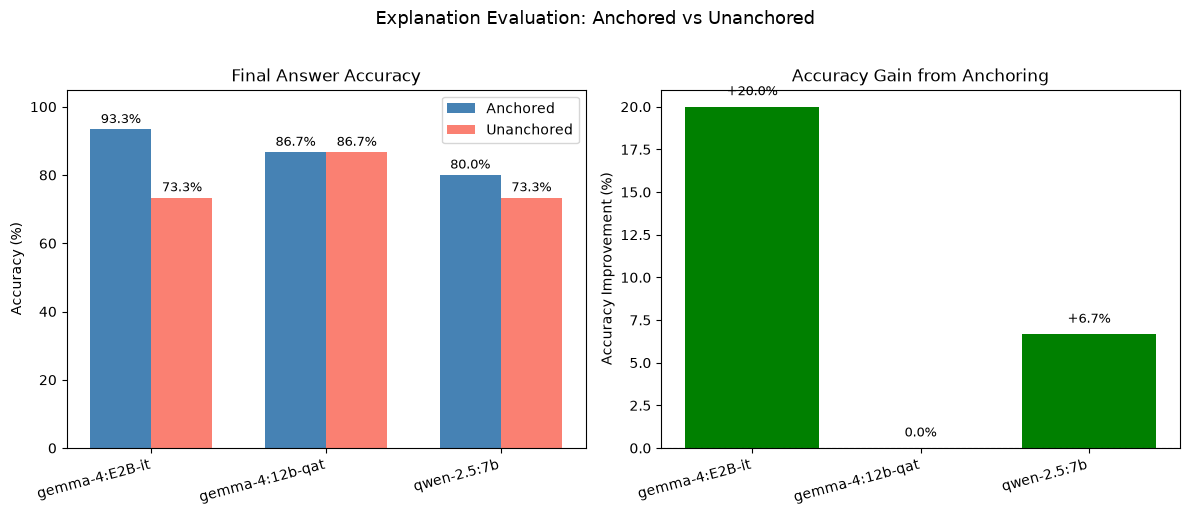

In [ ]:
# Short display names for charts
short_names = {
    'gemma-4-12b-qat:latest': 'gemma-4:12b-qat',
    'qwen2.5_7b-instruct': 'qwen-2.5:7b',
    'hf.co_unsloth_gemma-4-E2B-it-GGUF_Q4_K_M': 'gemma-4:E2B-it',
}
comparison_df['short'] = comparison_df['model'].map(short_names).fillna(comparison_df['model'])

x = range(len(comparison_df))
w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
bars_a = ax.bar([i - w/2 for i in x], comparison_df['anchored_pct'], w, label='Anchored', color='steelblue')
bars_u = ax.bar([i + w/2 for i in x], comparison_df['unanchored_pct'], w, label='Unanchored', color='salmon')
ax.set_xticks(list(x))
ax.set_xticklabels(comparison_df['short'], rotation=15, ha='right', fontsize=10)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Final Answer Accuracy')
ax.set_ylim(0, 105)
ax.legend(fontsize=10)
for bar, val in zip(bars_a, comparison_df['anchored_pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9)
for bar, val in zip(bars_u, comparison_df['unanchored_pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9)

ax = axes[1]
colors_imp = ['green' if v > 0 else 'red' for v in comparison_df['improvement']]
bars = ax.bar(list(x), comparison_df['improvement'], color=colors_imp)
ax.set_xticks(list(x))
ax.set_xticklabels(comparison_df['short'], rotation=15, ha='right', fontsize=10)
ax.set_ylabel('Accuracy Improvement (%)')
ax.set_title('Accuracy Gain from Anchoring')
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)
for bar, val in zip(bars, comparison_df['improvement']):
    offset = 0.5 if val >= 0 else -1.5
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset,
            f'+{val:.1f}%' if val > 0 else f'{val:.1f}%',
            ha='center', va='bottom', fontsize=9)

plt.suptitle('Explanation Evaluation: Anchored vs Unanchored', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('explanation_accuracy', dpi=300, bbox_inches='tight')
plt.show()

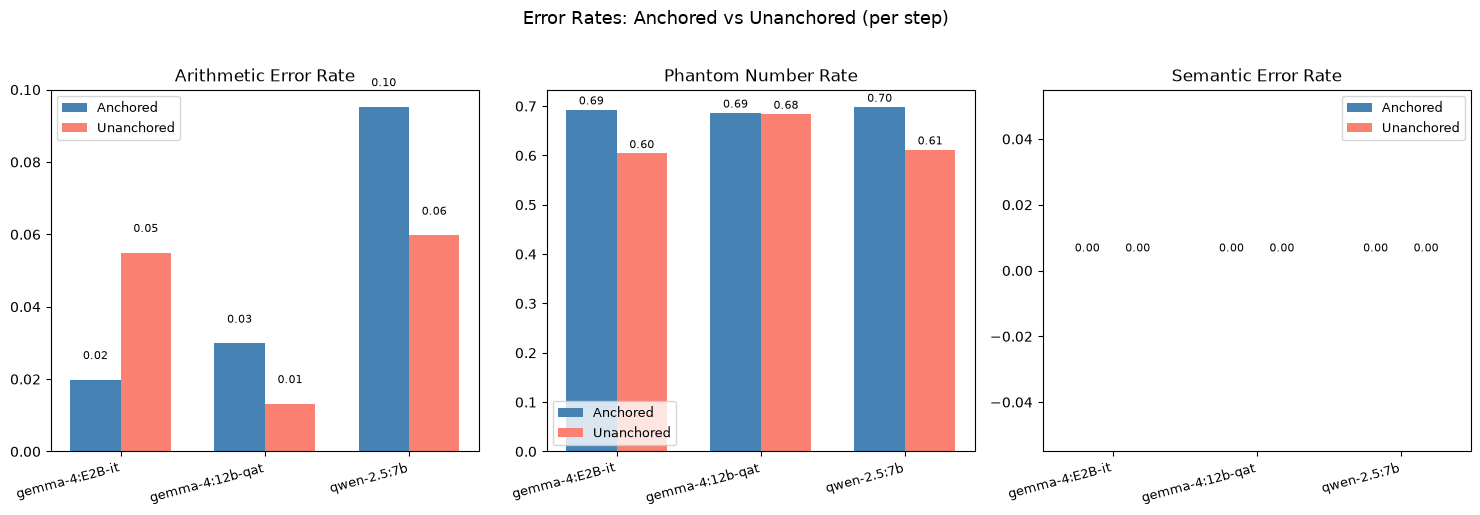

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

error_metrics = [
    ('a_arith_err', 'u_arith_err', 'Arithmetic Error Rate'),
    ('a_phantom', 'u_phantom', 'Phantom Number Rate'),
    ('a_sem_err', 'u_sem_err', 'Semantic Error Rate'),
]

for ax, (a_col, u_col, title) in zip(axes, error_metrics):
    bars_a = ax.bar([i - w/2 for i in x], comparison_df[a_col], w, label='Anchored', color='steelblue')
    bars_u = ax.bar([i + w/2 for i in x], comparison_df[u_col], w, label='Unanchored', color='salmon')
    ax.set_xticks(list(x))
    ax.set_xticklabels(comparison_df['short'], rotation=15, ha='right', fontsize=9)
    ax.set_title(title)
    ax.legend(fontsize=9)
    for bar, val in zip(bars_a, comparison_df[a_col]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.2f}', ha='center', va='bottom', fontsize=8)
    for bar, val in zip(bars_u, comparison_df[u_col]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.2f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Error Rates: Anchored vs Unanchored (per step)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('explanation_error_rates', dpi=300, bbox_inches='tight')
plt.show()